# Panorama de preços por categoria

Este notebook simula a consulta da equipe de pricing ao PostgreSQL da atividade.
Ele lê o snapshot diário mais recente e as últimas observações do histórico, com
o usuário `pricing_reader`. Execute todas as células com **Run All** no Dev Container
ou use `make notebook` no terminal da máquina.

## 1. Conexão e parâmetros

A janela do histórico termina na data do último snapshot.

In [1]:
import os
from datetime import timedelta
from html import escape

import matplotlib.pyplot as plt
import psycopg
from IPython.display import HTML, display
from psycopg.rows import namedtuple_row

dsn = os.environ["PRICING_ANALYTICS_DSN"]
dias_historico = 30

## 2. Snapshot mais recente

`precos_diarios` tem uma linha por data de referência em Brasília e categoria.
Os valores usam a unidade da FakeStore API. A média tem duas casas decimais.

In [2]:
with psycopg.connect(dsn, row_factory=namedtuple_row, connect_timeout=5) as conexao:
    snapshot = conexao.execute(
        '''
        SELECT data_referencia, categoria, quantidade, preco_medio, preco_minimo, preco_maximo
        FROM precos_diarios
        WHERE data_referencia = (SELECT max(data_referencia) FROM precos_diarios)
        ORDER BY preco_medio DESC, categoria
        '''
    ).fetchall()

referencia = snapshot[0].data_referencia if snapshot else None
if snapshot:
    quantidade = sum(linha.quantidade for linha in snapshot)
    print(f"{referencia:%d/%m/%Y} · {quantidade} produtos em {len(snapshot)} categorias")
    cabecalho = "<tr><th>Categoria</th><th>Produtos</th><th>Média</th><th>Mínimo</th><th>Máximo</th></tr>"
    linhas = "".join(
        f"<tr><td>{escape(row.categoria)}</td><td>{row.quantidade}</td>"
        f"<td>{row.preco_medio}</td><td>{row.preco_minimo}</td><td>{row.preco_maximo}</td></tr>"
        for row in snapshot
    )
    display(HTML(f"<table>{cabecalho}{linhas}</table>"))
else:
    print("Aguarde uma execução bem-sucedida da DAG e rode o notebook novamente.")

23/11/2026 · 20 produtos em 4 categorias


Categoria,Produtos,Média,Mínimo,Máximo
electronics,6,332.50,64,999.99
jewelery,4,221.00,9.99,695
men's clothing,4,51.06,15.99,109.95
women's clothing,6,26.29,7.95,56.99


## 3. Compare média e faixa de preços

A linha cobre o mínimo e o máximo observados. O ponto marca a média.

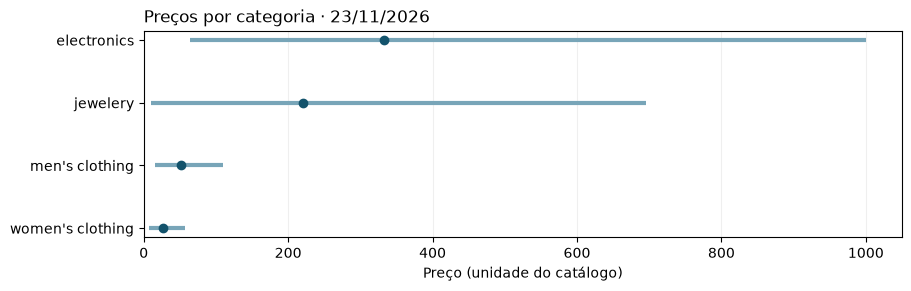

Maior média do snapshot: electronics (332.50).


In [3]:
if snapshot:
    fig, ax = plt.subplots(figsize=(9, max(2.8, len(snapshot) * 0.45)), layout="constrained")
    for posicao, linha in enumerate(snapshot):
        ax.hlines(posicao, float(linha.preco_minimo), float(linha.preco_maximo),
                  color="#78a5b8", linewidth=3)
        ax.scatter(float(linha.preco_medio), posicao, color="#13536c", zorder=3)
    ax.set_yticks(range(len(snapshot)), [linha.categoria for linha in snapshot])
    ax.invert_yaxis()
    ax.set_xlim(left=0)
    ax.set_title(f"Preços por categoria · {referencia:%d/%m/%Y}", loc="left")
    ax.set_xlabel("Preço (unidade do catálogo)")
    ax.grid(axis="x", alpha=0.2)
    plt.show()

    maior = snapshot[0]
    print(f"Maior média do snapshot: {maior.categoria} ({maior.preco_medio}).")

## 4. Explore o histórico de uma categoria

Escolha uma categoria ou mantenha a de maior média no snapshot.
O histórico usa a última observação publicada por data de referência.
Cada ponto corresponde a uma data coletada, incluindo quando há lacunas entre as coletas.

In [4]:
categoria = snapshot[0].categoria if snapshot else None
if categoria:
    inicio = referencia - timedelta(days=dias_historico - 1)
    with psycopg.connect(dsn, row_factory=namedtuple_row, connect_timeout=5) as conexao:
        historico = conexao.execute(
            '''
            SELECT DISTINCT ON (data_referencia) data_referencia, preco_medio, quantidade
            FROM precos_historico
            WHERE categoria = %s AND data_referencia BETWEEN %s AND %s
            ORDER BY data_referencia, data_execucao DESC, run_id COLLATE "C" DESC
            ''',
            (categoria, inicio, referencia),
        ).fetchall()

    print(f"{categoria} · {len(historico)} datas entre {inicio:%d/%m} e {referencia:%d/%m}")
    if len(historico) >= 2:
        fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
        ax.scatter(
            [linha.data_referencia for linha in historico],
            [float(linha.preco_medio) for linha in historico],
            color="#13536c",
        )
        ax.set_title(f"Preço médio observado · {categoria}", loc="left")
        ax.set_xlabel("Data de referência")
        ax.set_ylabel("Preço (unidade do catálogo)")
        ax.grid(axis="y", alpha=0.2)
        fig.autofmt_xdate()
        plt.show()
    else:
        print("O histórico precisa de pelo menos duas datas para comparar os preços.")

electronics · 1 datas entre 25/10 e 23/11
O histórico precisa de pelo menos duas datas para comparar os preços.


## 5. Interprete o resultado

Compare categorias pelo volume e pela faixa de preços no mesmo dia. Use os pontos
históricos para verificar como a média e o próprio catálogo mudam entre as coletas.
Produtos que entram ou saem da categoria também podem alterar a média.